In [1]:
import numpy as np

In [2]:
X_train = np.array([
    [800, 2],
    [1000, 2],
    [1200, 3],
    [1500, 3],
    [1800, 4]
], dtype=float)

y_train = np.array([40, 50, 65, 80, 100], dtype=float)

X_test = np.array([
    [900, 2],
    [1300, 3],
    [1700, 4]
], dtype=float)

y_test = np.array([45, 70, 95], dtype=float)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 5
Testing samples: 3


In [3]:
mean_X = np.mean(X_train, axis=0)
std_X = np.std(X_train, axis=0)

X_train_scaled = (X_train - mean_X) / std_X
X_test_scaled = (X_test - mean_X) / std_X

print("Training feature means:", mean_X)
print("Training feature standard deviations:", std_X)
print("\nScaled training data:\n", X_train_scaled)

Training feature means: [1260.     2.8]
Training feature standard deviations: [355.52777669   0.74833148]

Scaled training data:
 [[-1.29385109 -1.06904497]
 [-0.73130714 -1.06904497]
 [-0.16876319  0.26726124]
 [ 0.67505274  0.26726124]
 [ 1.51886867  1.60356745]]


In [4]:
w = np.zeros(X_train.shape[1])
b = 0.0

learning_rate = 0.01
epochs = 10000

print("Initial weights:", w)
print("Initial bias:", b)

Initial weights: [0. 0.]
Initial bias: 0.0


In [5]:
n = len(y_train)
loss_history = []

for epoch in range(epochs):

    # 1. Calculate predictions
    predictions = []

    for i in range(n):
        y_pred = np.dot(X_train_scaled[i], w) + b
        predictions.append(y_pred)

    predictions = np.array(predictions)

    # 2. Calculate errors
    errors = y_train - predictions

    # 3. Calculate Mean Squared Error
    mse = np.mean(errors ** 2)
    loss_history.append(mse)

    # 4. Calculate gradients
    gradient_w = (-2 / n) * np.dot(X_train_scaled.T, errors)
    gradient_b = (-2 / n) * np.sum(errors)

    # 5. Update weights and bias
    w = w - learning_rate * gradient_w
    b = b - learning_rate * gradient_b

print("Learned weights:", w)
print("Learned bias:", b)
print("Final training MSE:", loss_history[-1])

Learned weights: [17.77620855  3.74183767]
Learned bias: 66.99999999999966
Final training MSE: 3.4406540774068013e-09


In [6]:
test_predictions = []

for i in range(len(X_test_scaled)):
    y_pred = np.dot(X_test_scaled[i], w) + b
    test_predictions.append(y_pred)

test_predictions = np.array(test_predictions)

test_mse = np.mean((y_test - test_predictions) ** 2)

print("Actual prices:   ", y_test)
print("Predicted prices:", np.round(test_predictions, 2))
print("Test MSE:", test_mse)

Actual prices:    [45. 70. 95.]
Predicted prices: [45. 70. 95.]
Test MSE: 1.7450181888570467e-09


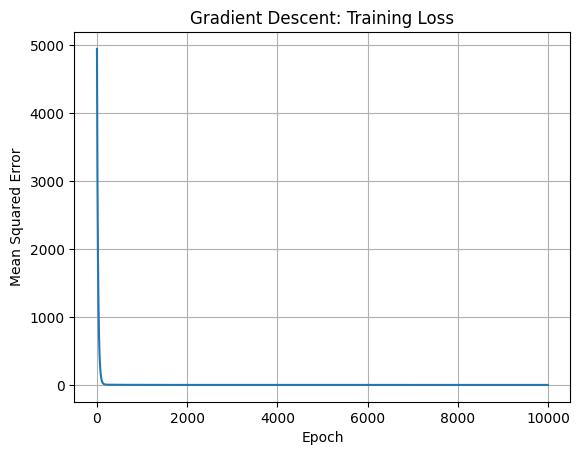

In [7]:
import matplotlib.pyplot as plt

plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent: Training Loss")
plt.grid(True)
plt.show()